# NewsBot Intelligence System 2.0
### Advanced NLP Integration and Analysis Platform

**José Miguel Tuozzo Izaguirre · ITAI 2373 — Natural Language Processing**  
Houston Community College | Final Capstone | November 2026

---

> **Executive overview.** NewsBot integrates content analysis, language understanding and generation, multilingual intelligence, and conversational information retrieval into one reproducible analytical workflow. This notebook is the unified research and demonstration companion to the complete software repository.

| Deliverable | Access |
| :--- | :--- |
| Canonical source | [GitHub repository](https://github.com/jtuozzo1616/Final-Jose-Group-NewsBot-Intelligence-System) |
| Individual portfolio | [ITAI2373-NewsBot-Final](https://github.com/jtuozzo1616/Jose-Tuozzo-AI-Portfolio/tree/main/ITAI2373-NewsBot-Final) |
| Detailed assessment | [Rubric crosswalk](https://github.com/jtuozzo1616/Final-Jose-Group-NewsBot-Intelligence-System/blob/main/final-newsbot-2.0/docs/CANVAS_VERIFICATION.md) |
| Verified execution | [33-test CI run](https://github.com/jtuozzo1616/Final-Jose-Group-NewsBot-Intelligence-System/actions/runs/45691589132) |

### Reader's guide

This single notebook integrates the seven topic-specific tutorials and the final system notebook. Each section executes the actual project library in the current kernel; the results are not fabricated. The default CPU workflow needs no paid API. Archived neural and real-data evidence is identified by source revision. Optional reruns are explicitly controlled in the setup cell.

**Reproducibility:** Runtime → Run all. After execution, File → Download → Download .ipynb to save the notebook with its actual output cells. Keep those outputs visible for assessment.

## Contents

1. **Data exploration and preprocessing** — quality, provenance, language and category distributions
2. **Advanced classification** — TF-IDF, hierarchy, confidence, out-of-fold evaluation and error analysis
3. **Topic modeling and advanced analytics** — LDA, NMF, clustering, temporal evolution, sentiment and entity co-mentions
4. **Language models** — MMR summarization, generation, query expansion and semantic retrieval
5. **Multilingual analysis** — language detection, translation, embeddings and shared-event coverage
6. **Conversational interface** — evidence retrieval, follow-up, intent routing, abstention and export
7. **System integration and research** — ablation, real historical benchmark, verification and frontend evidence
8. **Final synthesis** — academic conclusions, limitations, reproducibility and evidence export

### System architecture

`Validated CSV/JSONL → Normalization + source fingerprint → Classification / LDA & NMF / sentiment / entities → Lexical or learned retrieval → Grounded chat and structured reports → Web / API / CLI`

### Evidence boundaries

- **30 fictional articles:** controlled functional tests, not real-world accuracy.
- **10 fictional contextual records:** three-month, multilingual shared-event illustration; not real news trends.
- **250 historical BBC articles:** aggregate real-data cross-validation from an independently executed CI job. No copyrighted article bodies are republished.
- **288 historical BBC holdout articles:** distinct midterm evaluation; do not compare protocols as if they were the same test.

## 00 · Reproducible environment

The exact revision below is the one used by the previously successful eight-notebook Colab runner. The main CPU workflow executes all seven technical stages. Enable optional reruns to reproduce actual neural inference or the historical data experiment if network access and time permit; their archived results remain clearly identified when reruns are disabled.

In [1]:
from pathlib import Path
import os, sys, subprocess, json, time, platform
# Optional downloads and model inference. Keep False for the standard CPU review.
RERUN_NEURAL = False # @param {type:"boolean"}
RERUN_REAL_BBC = False # @param {type:"boolean"}
REPO_URL = 'https://github.com/jtuozzo1616/Final-Jose-Group-NewsBot-Intelligence-System.git'
REVISION = '5e415062572ff7e570fd48586cb7d07843ecccd1'
BASE = Path('/content') if Path('/content').is_dir() else Path.cwd()
REPO = BASE / ('NewsBot_Colab_' + REVISION[:8])
if not (REPO/'.git').is_dir():
    REPO.mkdir(parents=True, exist_ok=True)
    subprocess.run(['git','init',str(REPO)],check=True)
    subprocess.run(['git','-C',str(REPO),'remote','add','origin',REPO_URL],check=True)
    subprocess.run(['git','-C',str(REPO),'fetch','--depth=1','origin',REVISION],check=True)
    subprocess.run(['git','-C',str(REPO),'checkout','--detach','FETCH_HEAD'],check=True)
actual = subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip()
assert actual == REVISION, f'Unexpected source revision: {actual}'
ROOT = REPO/'final-newsbot-2.0'
subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(ROOT/'requirements-dev.txt'),'matplotlib'],check=True)
os.chdir(ROOT); sys.path.insert(0,str(ROOT))
from IPython.display import display, Markdown, Image
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from newsbot2.io import import_articles
from newsbot2.engine import NewsBotEngine
from newsbot2.analysis import summarize, sentiment, entities
from newsbot2.advanced import (discover_topics, sentiment_timeline, entity_network,
    language_comparison, structured_query, expand_query, hierarchy, export_report, compare_event_coverage)
from newsbot2.evaluation import evaluate_classification_cv
from newsbot2.language import detect_language, pivot_terms
from datetime import date, datetime, timezone
OUT = BASE / ('NewsBot_Master_Evidence_' + REVISION[:8]); OUT.mkdir(exist_ok=True)
FIG = OUT/'figures'; FIG.mkdir(exist_ok=True)
STAGES = []
NAVY, TEAL, BLUE, AMBER = '#172B45','#008C87','#6086AB','#D99B42'
plt.rcParams.update({'figure.dpi':125,'axes.spines.top':False,'axes.spines.right':False,
                     'axes.titleweight':'bold','axes.labelcolor':NAVY,'text.color':NAVY,
                     'axes.titlesize':13,'font.size':10,'axes.grid':False})
def finish(fig,name):
    fig.tight_layout(); fig.savefig(FIG/(name+'.png'),dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig)
def saved_json(name,data):
    (OUT/name).write_text(json.dumps(data,indent=2,ensure_ascii=False,default=str),encoding='utf-8')
def completed(number,name):
    STAGES.append({'section':number,'name':name,'status':'PASS'}); print(f'PASS | {number:02d} | {name}')
def evidence(name):
    return json.loads((ROOT/'evidence'/name).read_text(encoding='utf-8'))
def table(df):
    display(df.reset_index(drop=True) if isinstance(df,pd.DataFrame) else df)
def heatmap(matrix,labels,title,name,fmt='.2f',vmin=None,vmax=None):
    matrix=np.asarray(matrix); fig,ax=plt.subplots(figsize=(7.2,5.6))
    im=ax.imshow(matrix,cmap='Blues',vmin=vmin,vmax=vmax)
    ax.set_xticks(range(len(labels)),labels,rotation=25,ha='right'); ax.set_yticks(range(len(labels)),labels)
    mid=(float(matrix.min())+float(matrix.max()))/2
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j,i,format(matrix[i,j],fmt),ha='center',va='center',color='white' if matrix[i,j]>mid else NAVY)
    ax.set_title(title,pad=15); fig.colorbar(im,ax=ax,shrink=.75); finish(fig,name)
print('Source revision:',actual)
print('Python:',platform.python_version())
print('Dependencies available; CPU workflow ready.')

Source revision: 5e415062572ff7e570fd48586cb7d07843ecccd1
Python: 3.13.18
Dependencies available; CPU workflow ready.


## 01 · Data exploration and preprocessing

**Objective:** establish a reliable corpus before fitting models. The pipeline validates required fields, rejects duplicate IDs, cleans text, maintains source metadata, and generates SHA-256 fingerprints. The fingerprint supports content integrity checks but does not authenticate a publisher or determine truth.

,check,value
0,Unique article IDs,30
1,Validated body length,211
2,Explicitly fictional records,30
3,Dated contextual records,10


,article_id,title,language,category,words
0,demo-tech-1,Engineers test low-power AI chips,en,tech,39
1,demo-tech-2,Robotics lab demonstrates safer indoor navigation,en,tech,39
2,demo-tech-3,Researchers explore privacy-preserving data tools,en,tech,31
3,demo-tech-4,Campus software group studies accessible inter...,en,tech,33
4,demo-tech-5,Startup team prototypes satellite mapping soft...,en,tech,35
5,demo-business-1,Regional cooperative reports new store openings,en,business,34
6,demo-business-2,Small manufacturers review factory energy costs,en,business,34
7,demo-business-3,Bank pilots new small-business loan dashboard,en,business,33


Preprocessing example: NewsBot editorial analysis.
First article SHA-256: c4e7d2bf53009bc237f26731d2842a082e621cfe79588f52a06c435245fed5b4


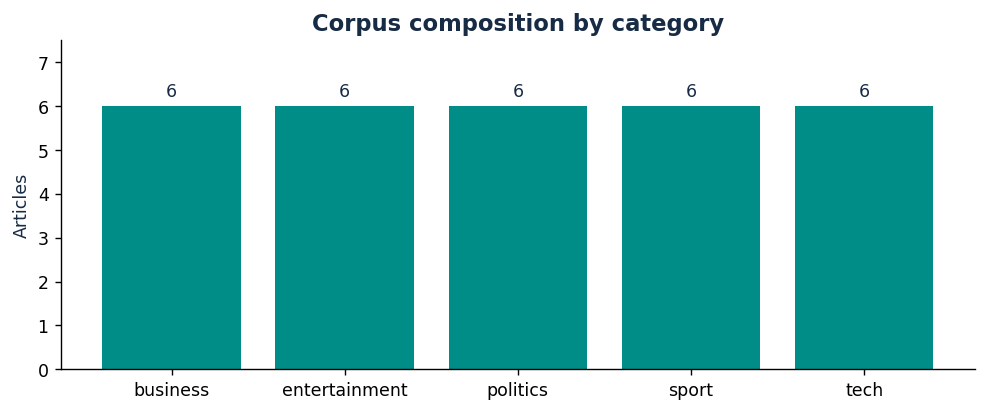

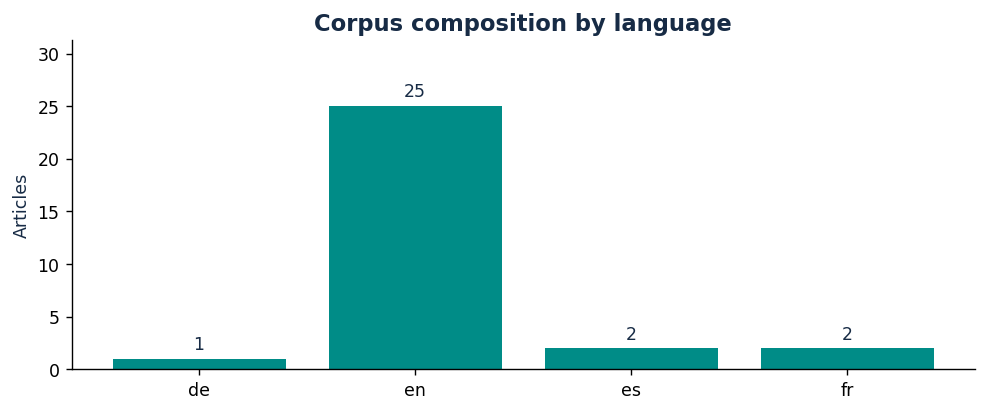

category,business,entertainment,politics,sport,tech
language,,,,,
de,0,0,0,1,0
en,5,5,5,5,5
es,1,0,0,0,1
fr,0,1,1,0,0


PASS | 01 | Data exploration and preprocessing


In [2]:
from newsbot2.schemas import normalize_text
articles=import_articles(ROOT/'data/demo_news.jsonl')
timeline=import_articles(ROOT/'data/demo_timeline.jsonl')
engine=NewsBotEngine(articles)
assert len(articles)==30 and all(a.synthetic for a in articles)
assert len(timeline)==10 and all(a.synthetic for a in timeline)
df=pd.DataFrame([a.to_dict() for a in articles]); df['words']=df.body.str.split().str.len()
assert df.article_id.is_unique and df.body.str.len().min()>=30
quality=pd.DataFrame({'check':['Unique article IDs','Validated body length','Explicitly fictional records','Dated contextual records'],
                      'value':[df.article_id.nunique(),int(df.body.str.len().min()),int(df.synthetic.sum()),len(timeline)]})
table(quality); table(df[['article_id','title','language','category','words']].head(8))
print('Preprocessing example:',normalize_text('  <b>NewsBot</b>   editorial analysis.  '))
print('First article SHA-256:',articles[0].sha256)
for series,title,name in [(df.category.value_counts().sort_index(),'Corpus composition by category','01_categories'),(df.language.value_counts().sort_index(),'Corpus composition by language','02_languages')]:
    fig,ax=plt.subplots(figsize=(8,3.4)); bars=ax.bar(series.index,series.values,color=TEAL); ax.bar_label(bars,padding=3); ax.set_ylim(0,max(series.values)*1.25); ax.set_ylabel('Articles'); ax.set_title(title); finish(fig,name)
coverage=pd.crosstab(df.language,df.category); display(coverage)
saved_json('01_overview.json',engine.overview()); df[['article_id','title','language','category','words']].to_csv(OUT/'corpus_metadata.csv',index=False)
completed(1,'Data exploration and preprocessing')

**Interpretation.** Categories are balanced by construction, while language support is uneven. A balanced class distribution is useful for a controlled demonstration but does not represent a natural news distribution. The synthetic flag must accompany downstream interpretations.

## 02 · Advanced classification

TF-IDF represents word importance; logistic regression predicts the child category, while a documented taxonomy maps it to the parent category. Ranking scores are uncalibrated. Stratified three-fold cross-validation estimates out-of-fold predictions with feature fitting inside each fold; the local model fitted for demonstration must not be treated as a holdout evaluation.

,category,score
0,tech,0.3777
1,sport,0.1584
2,business,0.1552
3,politics,0.1544
4,entertainment,0.1542


{'parent_category': 'science and technology',
 'child_category': 'tech',
 'score_type': 'model-estimated-probabilities; uncalibrated',
 'confidence_gap': 0.2193,
 'method': 'fixed taxonomy, classifier scores uncalibrated'}

,TF-IDF feature,weight
0,power,0.3056
1,low,0.1528
2,computer chip,0.1528
3,low power,0.1528
4,measured processing,0.1528
5,chips university,0.1528
6,chips,0.1528
7,chip designed,0.1528
8,chip,0.1528
9,conditions,0.1528


,precision,recall,f1-score,support
business,0.500,0.167,0.250,6.0
entertainment,0.400,0.333,0.364,6.0
politics,0.444,0.667,0.533,6.0
sport,0.714,0.833,0.769,6.0
tech,0.714,0.833,0.769,6.0


Synthetic OOF accuracy: 0.5667 | macro-F1: 0.5371


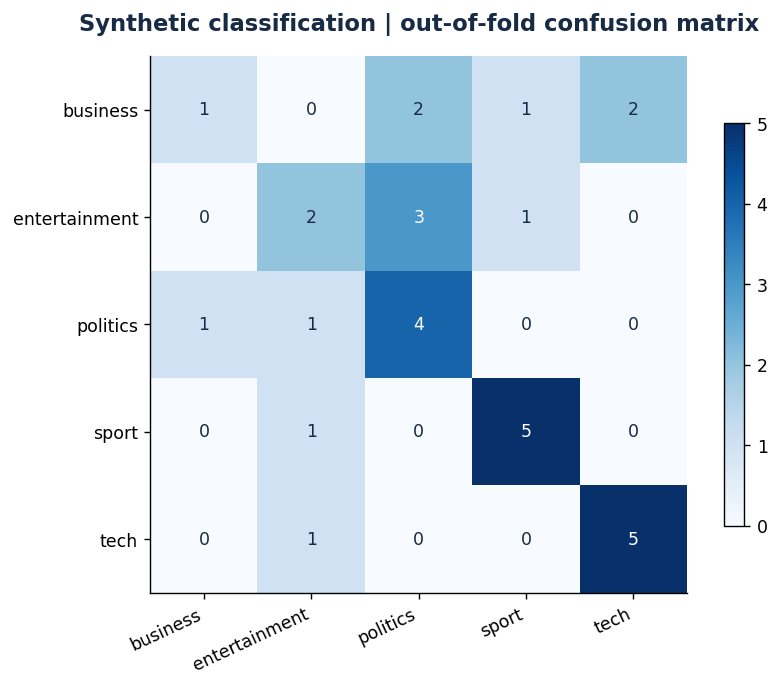

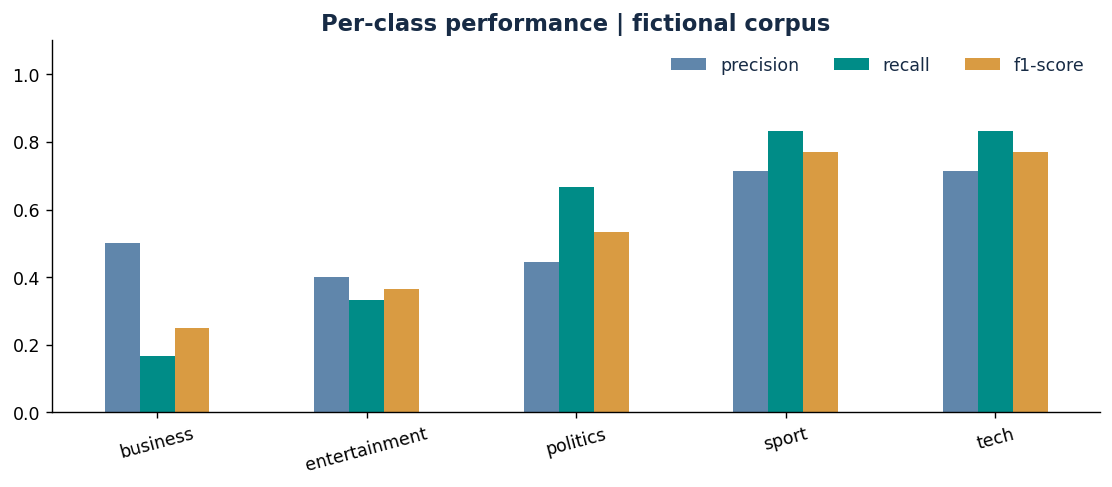

PASS | 02 | Advanced classification


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
train=engine.train_local_classifier(); assert train['status']=='trained'
analysis=engine.analyze('demo-tech-1'); pred=analysis['classification']
table(pd.DataFrame(pred['ranked_scores'])); display(hierarchy(pred))
vec=TfidfVectorizer(ngram_range=(1,2),stop_words='english',max_features=1000)
X=vec.fit_transform([a.full_text for a in articles]); first=X[0].toarray().ravel(); idx=first.argsort()[-10:][::-1]
table(pd.DataFrame({'TF-IDF feature':vec.get_feature_names_out()[idx],'weight':first[idx]}).round(4))
cv=evaluate_classification_cv(articles,folds=3); assert cv['status']=='ok'
report=pd.DataFrame(cv['per_class']).T.loc[cv['classes'],['precision','recall','f1-score','support']]
display(report.round(3)); print('Synthetic OOF accuracy:',cv['accuracy'],'| macro-F1:',cv['macro_f1'])
heatmap(cv['confusion_matrix'],cv['classes'],'Synthetic classification | out-of-fold confusion matrix','03_synthetic_confusion',fmt='d')
fig,ax=plt.subplots(figsize=(9,4)); report[['precision','recall','f1-score']].plot.bar(ax=ax,color=[BLUE,TEAL,AMBER],rot=15); ax.set_ylim(0,1.1); ax.set_title('Per-class performance | fictional corpus'); ax.legend(frameon=False,ncol=3); finish(fig,'04_class_metrics')
saved_json('02_classification.json',cv); completed(2,'Advanced classification')

**Critical analysis.** Macro-F1 weights the classes equally; the confusion matrix exposes errors that aggregate accuracy can hide. The 30-record fixture cannot establish generalization to publishers, languages or events outside the dataset.

## 03 · Topic modeling, temporal analytics and entity relationships

LDA estimates distributions over topics using word counts; NMF decomposes a nonnegative TF-IDF matrix. Both produce exploratory topic terms and document weights. K-means groups the normalized document-topic distributions. Temporal analysis uses actual supplied dates and refuses to infer a trend from missing dates or insufficient periods.

### LDA — top terms and document allocation

,topic_id,terms,article_count
0,0,"team, proposal, public, small, fictional, cost...",9
1,1,"le, fictional, une, film, program, feedback, l...",9
2,2,"training, fictional, local, council, said, pro...",8
3,3,"organizers, event, student, university, public...",4


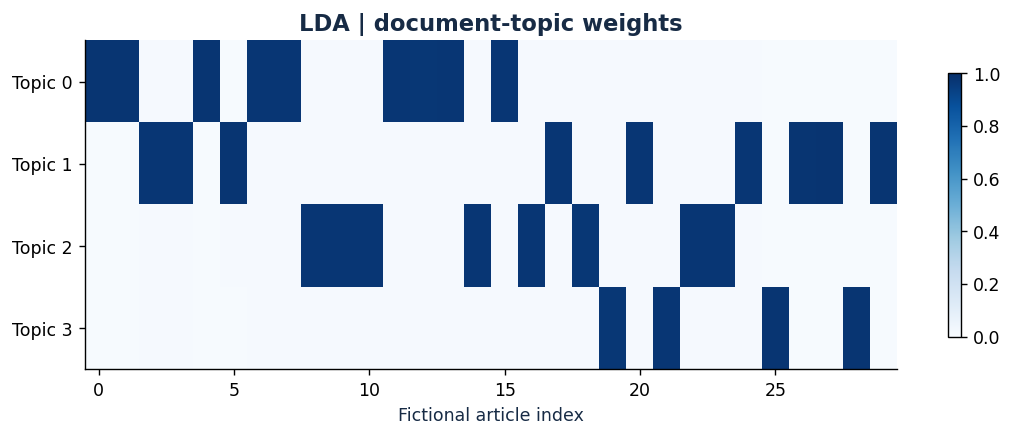

Uninformative distributions: 0


,article_id,cluster_id,topic_id
0,demo-tech-1,0,0
1,demo-tech-2,0,0
2,demo-tech-3,1,1
3,demo-tech-4,1,1
4,demo-tech-5,0,0
5,demo-business-1,1,1
6,demo-business-2,0,0
7,demo-business-3,0,0


### NMF — top terms and document allocation

,topic_id,terms,article_count
0,0,"training, local, said, club, event, digital, s...",10
1,1,"software, team, university, robotics, power, t...",9
2,2,"school, public, council, proposal, student, bu...",8
3,3,"le, une, les, film, des, programme, présente, ...",3


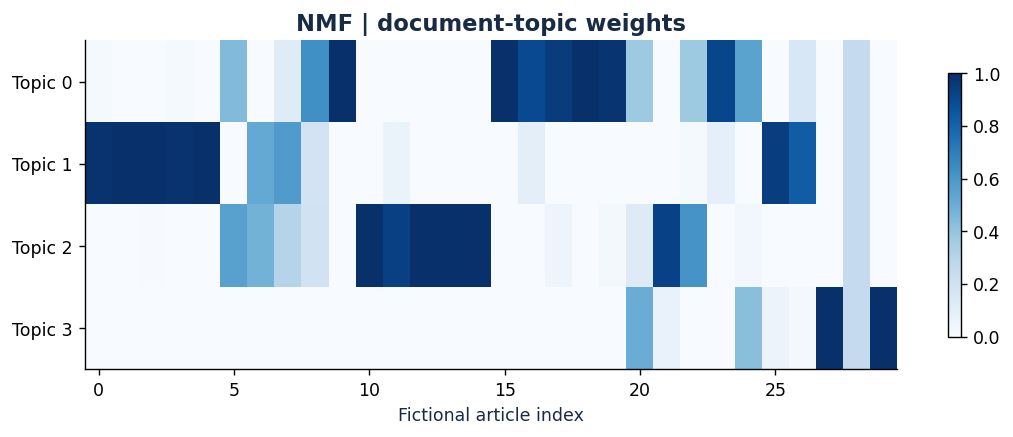

Uninformative distributions: 1


,article_id,cluster_id,topic_id
0,demo-tech-1,1,1
1,demo-tech-2,1,1
2,demo-tech-3,1,1
3,demo-tech-4,1,1
4,demo-tech-5,1,1
5,demo-business-1,2,2
6,demo-business-2,1,1
7,demo-business-3,1,1


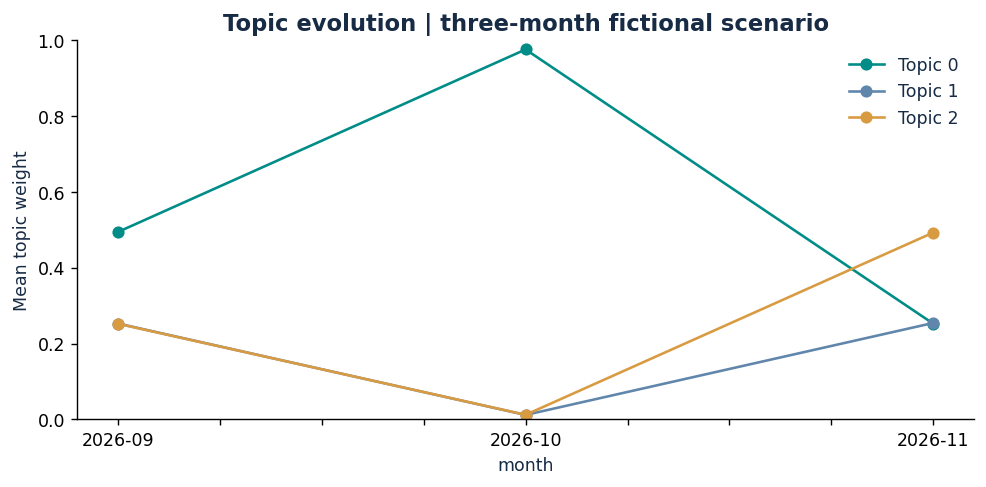

,month,method,n,mean_score
0,2026-09,weak-lexicon-fallback,4,0.0
1,2026-10,weak-lexicon-fallback,2,0.0
2,2026-11,weak-lexicon-fallback,4,0.0


Sentiment method: weak-lexicon-fallback | records: 10
Source-linked entity co-mentions: 40


,entity_a,entity_b,co_mentions,article_ids
0,Der Sportverein,Der Verein,1,[demo-sport-6]
1,Der Sportverein,Die Organisatoren,1,[demo-sport-6]
2,Der Sportverein,Freiwillige,1,[demo-sport-6]
3,Der Sportverein,Spieler,1,[demo-sport-6]
4,Der Sportverein,Spielplan,1,[demo-sport-6]
5,Der Sportverein,Sportverein,1,[demo-sport-6]
6,Der Sportverein,müssen,1,[demo-sport-6]
7,Der Verein,Die Organisatoren,1,[demo-sport-6]
8,Der Verein,Freiwillige,1,[demo-sport-6]
9,Der Verein,Spieler,1,[demo-sport-6]


PASS | 03 | Topic modeling and advanced analytics


In [4]:
topic_outputs={}
for method in ('lda','nmf'):
    result=discover_topics(articles,4,method); assert result['status']=='ok'; topic_outputs[method]=result
    topics=pd.DataFrame(result['topics']); topics['terms']=topics.terms.map(', '.join)
    display(Markdown('### '+method.upper()+' — top terms and document allocation')); display(topics)
    weights=np.array([d['distribution'] for d in result['documents']]); assert np.allclose(weights.sum(axis=1),1,atol=.001)
    fig,ax=plt.subplots(figsize=(9,3.6)); im=ax.imshow(weights.T,aspect='auto',cmap='Blues',vmin=0,vmax=1); ax.set_yticks(range(weights.shape[1]),[f'Topic {i}' for i in range(weights.shape[1])]); ax.set_xlabel('Fictional article index'); ax.set_title(method.upper()+' | document-topic weights'); fig.colorbar(im,ax=ax,shrink=.8); finish(fig,'05_'+method+'_weights')
    print('Uninformative distributions:',result['uninformative_documents'])
    table(pd.DataFrame(result['documents'])[['article_id','cluster_id','topic_id']].head(8))
dated=discover_topics(timeline,3,'lda'); assert dated['trend_status']=='descriptive' and len(dated['evolution'])==3
monthly=pd.DataFrame([{'month':r['month'],**{f'Topic {i}':w for i,w in enumerate(r['mean_topic_weights'])}} for r in dated['evolution']]).set_index('month')
fig,ax=plt.subplots(figsize=(8,4)); monthly.plot(ax=ax,marker='o',color=[TEAL,BLUE,AMBER]); ax.set_ylim(0,1); ax.set_title('Topic evolution | three-month fictional scenario'); ax.set_ylabel('Mean topic weight'); ax.legend(frameon=False); finish(fig,'06_topic_evolution')
tone=sentiment_timeline(timeline); table(pd.DataFrame(tone['rows']))
for method,group in pd.DataFrame(tone['rows']).groupby('method'):
    print('Sentiment method:',method,'| records:',group.n.sum())
edges=entity_network(articles); print('Source-linked entity co-mentions:',len(edges)); table(pd.DataFrame(edges))
saved_json('03_topics_and_context.json',{'topics':topic_outputs,'dated':dated,'sentiment':tone,'co_mentions':edges})
completed(3,'Topic modeling and advanced analytics')

**Interpretation.** Topic IDs are corpus-specific, not universal themes. NMF rows without active components receive an explicitly marked uniform prior. Source co-mentions describe textual associations, not real causal relationships. The dated scenario is fictional and supports a visualization demonstration only.

## 04 · Language understanding and generation

MMR extracts relevant source sentences with a redundancy penalty. Query expansion exposes added domain terms. TF-IDF and latent semantic analysis provide complementary retrieval baselines. Pretrained FLAN-T5 inference is represented by verified source-linked archived outputs, or may be rerun in this notebook with the optional setting.

In [5]:
article=engine.by_id['demo-tech-1']; display(Markdown('**Source article:** '+article.title+'  \n'+article.body))
summary=analysis['summary']; display(Markdown('**Extractive summary:** '+summary['text']))
table(pd.DataFrame({'suggested_headline':analysis['enhancement']['headlines']}))
print('Expansion:',expand_query('robot'))
lsa=NewsBotEngine(articles,retrieval_mode='lsa'); q='robot cameras sensors navigation'
for name,eng in [('Lexical',engine),('Latent semantic',lsa)]:
    display(Markdown('**'+name+' retrieval**')); table(pd.DataFrame(eng.search(q,k=3))[['article_id','title','score','retrieval_method']])
if RERUN_NEURAL:
    subprocess.run([sys.executable,'-m','pip','install','-q','transformers>=4.45,<5','sentencepiece','torch'],check=True)
    subprocess.run([sys.executable,'run_generation_evidence.py'],check=True)
gen=evidence('generation_results.json'); assert all(r['status']=='ok' for r in gen['results'])
print('FLAN-T5 evidence:', 'rerun in this runtime' if RERUN_NEURAL else 'archived verified GitHub inference', '| revision:',gen['commit'])
table(pd.DataFrame(gen['results'])[['source_id','draft','draft_vocabulary_overlap']]); print(gen['scope'])
saved_json('04_language_models.json',{'summary':summary,'generation_evidence':gen,'rerun_in_current_runtime':RERUN_NEURAL})
completed(4,'Language models and retrieval')

**Source article:** Engineers test low-power AI chips  
A university engineering team tested an experimental computer chip designed to reduce the energy required for artificial intelligence tasks. The study measured processing time and power consumption under laboratory conditions. The researchers plan another trial before any public release.

**Extractive summary:** A university engineering team tested an experimental computer chip designed to reduce the energy required for artificial intelligence tasks. The study measured processing time and power consumption under laboratory conditions. The researchers plan another trial before any public release.

,suggested_headline
0,Engineers test low-power AI chips
1,Briefing: Engineers test low-power AI chips
2,Explainer | Engineers test low-power AI chips


Expansion: {'original': 'robot', 'pivot': 'robot', 'added_terms': ['navigation', 'robotics', 'sensors'], 'expanded': 'robot navigation robotics sensors'}


**Lexical retrieval**

,article_id,title,score,retrieval_method
0,demo-tech-2,Robotics lab demonstrates safer indoor navigation,0.2927,tfidf-pivot
1,demo-tech-6,Universidad investiga robótica para navegación,0.0514,tfidf-pivot


**Latent semantic retrieval**

,article_id,title,score,retrieval_method
0,demo-tech-2,Robotics lab demonstrates safer indoor navigation,0.9871,lsa-svd-pivot
1,demo-tech-6,Universidad investiga robótica para navegación,0.1733,lsa-svd-pivot
2,demo-entertainment-2,Music school schedules public student concert,0.0142,lsa-svd-pivot


FLAN-T5 evidence: archived verified GitHub inference | revision: 41d85f7355d110439333a9e8b9c48ca7dbb78849


,source_id,draft,draft_vocabulary_overlap
0,demo-tech-1,A university engineering team has tested a low...,0.9474
1,demo-tech-2,A robotics lab demonstrates safer indoor navig...,1.0000
2,demo-tech-3,Computer scientists have published a simulated...,0.9333


Three actual neural drafts from fictional articles; no human-rated factuality or summarization accuracy claimed.
PASS | 04 | Language models and retrieval


**Interpretation.** A neural draft is not a verified fact. Lexical overlap is a diagnostic, not a factuality metric; inspect numbers, entities and claims against their sources. The extractive reference and source fingerprint are retained.

## 05 · Multilingual intelligence

Detect language hints, compare language coverage, inspect cross-language retrieval, translate with a real offline language model and examine a learned embedding similarity matrix. The default lexical pivot is not machine translation; the two mechanisms are explicitly distinguished.

Query: investigación de inteligencia artificial | detection: {'language': 'und', 'confidence': 'low', 'method': 'stopword-heuristic', 'scores': {'en': 0, 'es': 1, 'fr': 1, 'de': 0}}


,article_id,title,score
0,demo-tech-6,Universidad investiga robótica para navegación,0.1807
1,demo-tech-1,Engineers test low-power AI chips,0.1136
2,demo-business-2,Small manufacturers review factory energy costs,0.0495


Query: technologie robotique | detection: {'language': 'und', 'confidence': 'low', 'method': 'stopword-heuristic', 'scores': {'en': 0, 'es': 0, 'fr': 0, 'de': 0}}


,article_id,title,score
0,demo-tech-2,Robotics lab demonstrates safer indoor navigation,0.1356
1,demo-politics-5,Council considers school budget hearings,0.0885
2,demo-business-5,Local firms invest in employee training,0.0841


Query: forschung daten | detection: {'language': 'und', 'confidence': 'low', 'method': 'stopword-heuristic', 'scores': {'en': 0, 'es': 0, 'fr': 0, 'de': 0}}


,article_id,title,score
0,demo-tech-3,Researchers explore privacy-preserving data tools,0.2371
1,demo-business-2,Small manufacturers review factory energy costs,0.0692
2,demo-tech-5,Startup team prototypes satellite mapping soft...,0.0649


Spanish language filter:


,article_id,title,score,excerpt,source,synthetic,retrieval_method
0,demo-tech-6,Universidad investiga robótica para navegación,0.2998,Un equipo de la universidad desarrolló un robo...,Synthetic classroom demonstration — fictional,True,tfidf-pivot


,language,source_region,title,extractive_focus
0,en,US (fictional outlet),City launches electric shuttle pilot,The fictional transit office introduced electr...
1,es,Mexico (fictional outlet),Programa piloto de transporte eléctrico,El municipio ficticio presentó autobuses eléct...
2,fr,France (fictional outlet),Un essai de navettes électriques,La ville fictive a lancé un essai de navettes ...
3,de,Germany (fictional outlet),Pilotprojekt mit elektrischen Bussen,"Der Bericht betont die Ladeinfrastruktur, die ..."


Compare stated emphases and context manually. Region is source metadata, not a measure of cultural or political bias. Fictional examples do not describe actual populations.
MiniLM / Argos evidence: archived verified GitHub inference | revisions: 34334694ae29bff477b8c43462b14ad8a3077ddd 34334694ae29bff477b8c43462b14ad8a3077ddd


,source,translated_text,provider
0,La universidad investiga inteligencia artificial.,The university investigates artificial intelli...,argos-local
1,El equipo de robótica probó sensores y cámaras.,The robotics team tested sensors and cameras.,argos-local
2,Los periodistas verificaron las fuentes antes ...,The journalists checked the sources before the...,argos-local


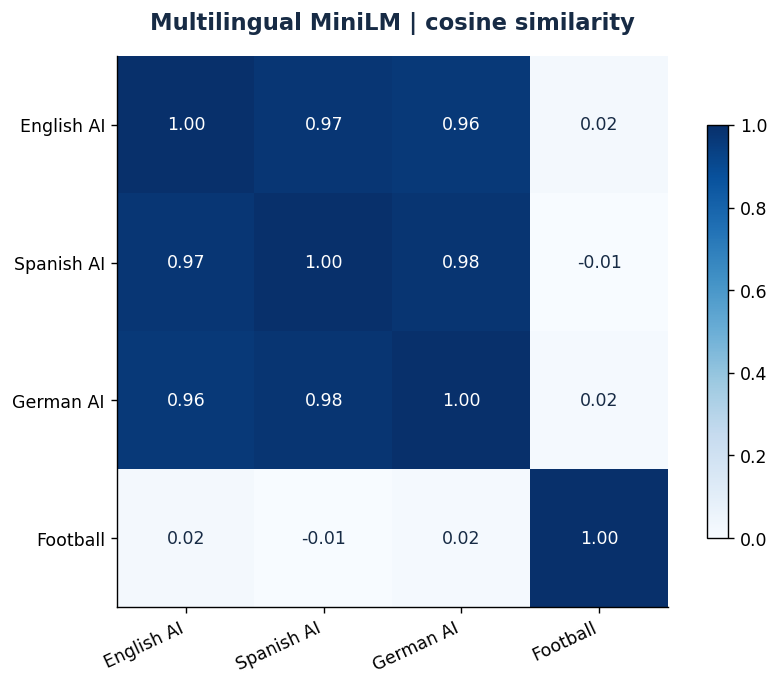

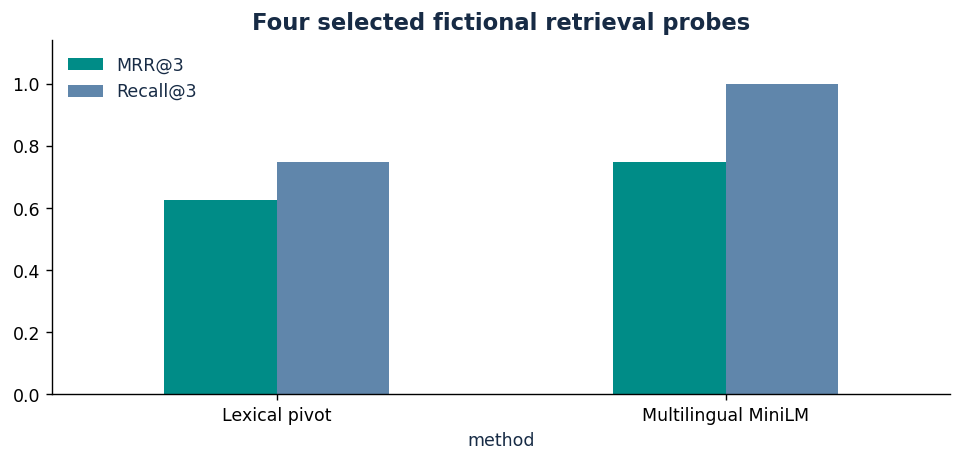

PASS | 05 | Multilingual intelligence


In [6]:
queries=['investigación de inteligencia artificial','technologie robotique','forschung daten']
for query in queries:
    print('Query:',query,'| detection:',detect_language(query)); table(pd.DataFrame(engine.search(query,k=3))[['article_id','title','score']])
print('Spanish language filter:'); table(pd.DataFrame(engine.search('robótica navegación universidad',k=3,language='es')))
shared=compare_event_coverage(timeline,'transit-pilot'); assert len(shared['sources'])==4
table(pd.DataFrame(shared['sources'])[['language','source_region','title','extractive_focus']]); print(shared['warning'])
if RERUN_NEURAL:
    subprocess.run([sys.executable,'-m','pip','install','-q','sentence-transformers>=3,<6','argostranslate>=1.9,<2'],check=True)
    subprocess.run([sys.executable,'run_neural_evidence.py'],check=True)
emb=evidence('embedding_results.json'); trans=evidence('translation_results.json')
assert emb['dimension']==384 and all(r['status']=='ok' for r in trans['translations'])
print('MiniLM / Argos evidence:', 'rerun in this runtime' if RERUN_NEURAL else 'archived verified GitHub inference', '| revisions:',emb['commit'],trans['commit'])
table(pd.DataFrame(trans['translations'])[['source','translated_text','provider']])
heatmap(emb['cosine_similarity'],['English AI','Spanish AI','German AI','Football'],'Multilingual MiniLM | cosine similarity','07_semantic_similarity',vmin=0,vmax=1)
comparative=pd.DataFrame([{'method':'Lexical pivot','MRR@3':emb['lexical_retrieval']['mrr_at_k'],'Recall@3':emb['lexical_retrieval']['recall_at_k']},{'method':'Multilingual MiniLM','MRR@3':emb['embedding_retrieval']['mrr_at_k'],'Recall@3':emb['embedding_retrieval']['recall_at_k']}]).set_index('method')
fig,ax=plt.subplots(figsize=(7.8,3.8)); comparative.plot.bar(ax=ax,rot=0,color=[TEAL,BLUE]); ax.set_ylim(0,1.14); ax.set_title('Four selected fictional retrieval probes'); ax.legend(frameon=False); finish(fig,'08_neural_retrieval')
saved_json('05_multilingual.json',{'embeddings':emb,'translation':trans,'shared_event':shared,'rerun_in_current_runtime':RERUN_NEURAL}); completed(5,'Multilingual intelligence')

**Interpretation.** High similarity among semantically related multilingual sentences demonstrates that the learned vectors can align meanings in this small example; it is not proof of comprehensive multilingual performance. The four retrieval probes are selected fictional cases. Regional source metadata supports comparative reading, not stereotypes or inference about a population.

## 06 · Conversational interface

Grounded chat uses retrieval and source excerpts. Follow-up queries can incorporate previous source context; structured queries support multiple intents, category, tone, date and user preferences. The correct behavior when evidence is weak is to abstain, not invent an answer.

In [7]:
chat_engine=NewsBotEngine(articles)
conversation=[]
for question in ['What did the AI chip researchers measure?','Tell me more','zzqxv nonexistent topic 0123456789']:
    answer=chat_engine.ask(question); conversation.append({'question':question,'response':answer})
    display(Markdown('**Question:** '+question+'  \n**Response:** '+answer['answer']))
    if answer['citations']: table(pd.DataFrame(answer['citations']))
    print('Status:',answer['status'])
assert conversation[0]['response']['citations'] and conversation[-1]['response']['status']=='insufficient_evidence'
structured=structured_query(chat_engine,'Compare tech topics across languages'); print('Intents:',structured['intent'],'| matched:',structured['matched']); table(pd.DataFrame(structured['articles']))
assert set(structured['intent']['intents'])=={'topics','compare'}
filtered=structured_query(chat_engine,'Show tech news this week',as_of=date(2027,1,1)); assert filtered['matched']==0
(OUT/'structured_query_report.json').write_text(export_report(structured),encoding='utf-8')
saved_json('06_conversation.json',conversation); completed(6,'Conversational interface')

**Question:** What did the AI chip researchers measure?  
**Response:** [demo-tech-1] A university engineering team tested an experimental computer chip designed to reduce the energy required for artificial intelligence tasks. The study measured processing time and power consumption under laboratory conditions.

,article_id,title,source,retrieval_score,synthetic
0,demo-tech-1,Engineers test low-power AI chips,Synthetic classroom demonstration — fictional,0.185,True


Status: grounded_extract


**Question:** Tell me more  
**Response:** [demo-tech-1] A university engineering team tested an experimental computer chip designed to reduce the energy required for artificial intelligence tasks. The study measured processing time and power consumption under laboratory conditions.

,article_id,title,source,retrieval_score,synthetic
0,demo-tech-1,Engineers test low-power AI chips,Synthetic classroom demonstration — fictional,0.4471,True


Status: grounded_extract


**Question:** zzqxv nonexistent topic 0123456789  
**Response:** I could not find adequate supporting material in the loaded articles. Please name a topic, entity or article title, or upload relevant sources.

Status: insufficient_evidence
Intents: {'intents': ['topics', 'compare'], 'category': 'tech', 'tone': None, 'this_week': False} | matched: 6


,article_id,title,source,published_at,synthetic
0,demo-tech-1,Engineers test low-power AI chips,Synthetic classroom demonstration — fictional,2026-11-01,True
1,demo-tech-2,Robotics lab demonstrates safer indoor navigation,Synthetic classroom demonstration — fictional,2026-11-01,True
2,demo-tech-3,Researchers explore privacy-preserving data tools,Synthetic classroom demonstration — fictional,2026-11-01,True
3,demo-tech-4,Campus software group studies accessible inter...,Synthetic classroom demonstration — fictional,2026-11-01,True
4,demo-tech-5,Startup team prototypes satellite mapping soft...,Synthetic classroom demonstration — fictional,2026-11-01,True
5,demo-tech-6,Universidad investiga robótica para navegación,Synthetic classroom demonstration — fictional,2026-11-01,True


PASS | 06 | Conversational interface


## 07 · System integration and experimental research

The integrated pipeline is evaluated from three perspectives: paired feature ablation on the synthetic fixture, real historical classification on a balanced BBC sample, and automated software verification. Distinct protocols are reported separately. Research questions are deliberately scoped to the supplied datasets.

,Accuracy,Macro-F1
Word TF-IDF,0.5667,0.5371
Pivot TF-IDF,0.6000,0.5720
Pivot + character,0.6667,0.6143


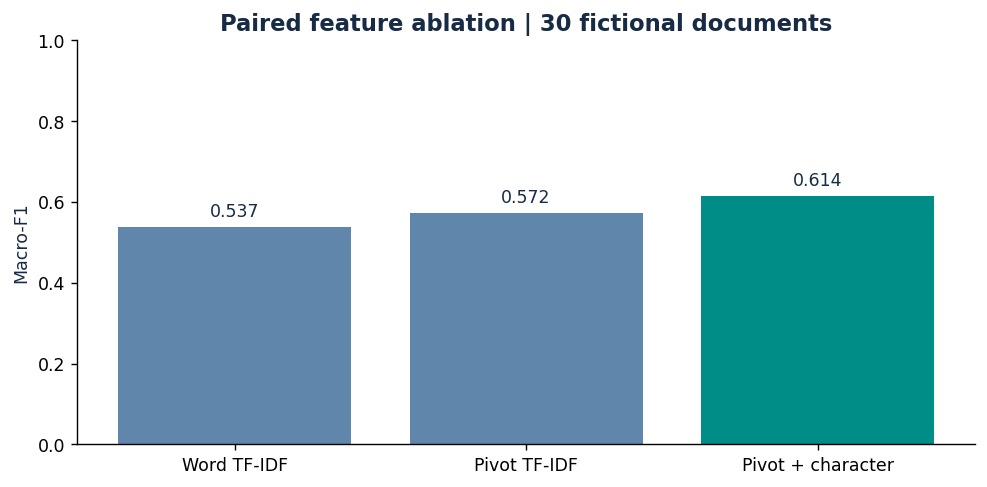

Selected 24-probe MRR@3: 1.0 with pivot / 0.625 without pivot
BBC evaluation: archived verified GitHub evaluation | revision: 41d85f7355d110439333a9e8b9c48ca7dbb78849
250 historical articles | accuracy: 0.908 | macro-F1: 0.9079


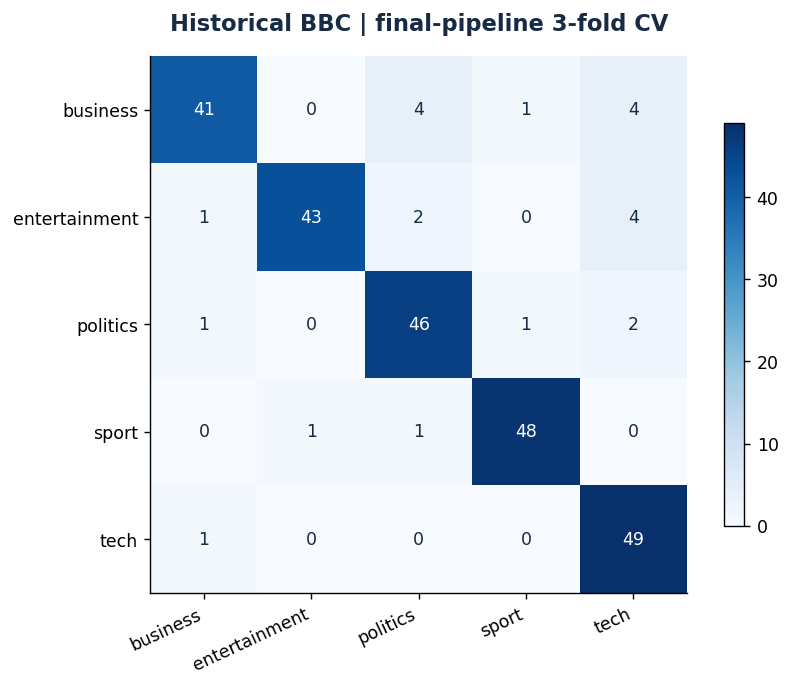

,precision,recall,f1-score,support
business,0.932,0.82,0.872,50.0
entertainment,0.977,0.86,0.915,50.0
politics,0.868,0.92,0.893,50.0
sport,0.960,0.96,0.960,50.0
tech,0.831,0.98,0.899,50.0


**Historical BBC — LDA topic terms**

,topic_id,terms,article_count
0,0,"[said, year, growth, sales, mr, economy, 2004,...",45
1,1,"[film, best, said, won, year, star, actor, awa...",38
2,2,"[said, mr, people, government, blair, election...",54
3,3,"[said, new, year, game, wales, people, win, mu...",65
4,4,"[said, new, mr, people, tv, broadband, mobile,...",48


**Historical BBC — NMF topic terms**

,topic_id,terms,article_count
0,0,"[broadband, people, music, said, bt, mobile, t...",66
1,1,"[film, best, actor, award, awards, star, won, ...",37
2,2,"[mr, blair, election, party, labour, lib, said...",45
3,3,"[match, rugby, final, win, cup, england, game,...",58
4,4,"[economy, growth, rates, bank, rate, economic,...",44


Historical benchmark scope: Balanced historical sample, not contemporary or multilingual validation. No copyrighted article bodies republished. Dates unknown; no fabricated trend data.


In [8]:
subprocess.run([sys.executable,'run_research.py'],check=True)
research=json.loads((ROOT/'artifacts/research_results.json').read_text()); paired=research['paired_multilingual_extension']['paired_oof']
ablation=pd.DataFrame({k:{'Accuracy':v['accuracy'],'Macro-F1':v['macro_f1']} for k,v in paired.items()}).T.rename(index={'baseline':'Word TF-IDF','pivot':'Pivot TF-IDF','pivot_char':'Pivot + character'})
display(ablation.round(4))
fig,ax=plt.subplots(figsize=(8,4)); bars=ax.bar(ablation.index,ablation['Macro-F1'],color=[BLUE,BLUE,TEAL]); ax.bar_label(bars,fmt='%.3f',padding=4); ax.set_ylim(0,1); ax.set_title('Paired feature ablation | 30 fictional documents'); ax.set_ylabel('Macro-F1'); finish(fig,'09_feature_ablation')
retrieval=research['retrieval_probes']; print('Selected 24-probe MRR@3:',retrieval['pivot_mrr'],'with pivot /',retrieval['naive_mrr'],'without pivot')
if RERUN_REAL_BBC: subprocess.run([sys.executable,'run_real_evidence.py'],check=True)
real=evidence('real_bbc_final_evaluation.json'); rcv=real['cv']; assert real['n']==250 and rcv['status']=='ok'
print('BBC evaluation:', 'rerun in this runtime' if RERUN_REAL_BBC else 'archived verified GitHub evaluation', '| revision:',real['commit'])
print('250 historical articles | accuracy:',rcv['accuracy'],'| macro-F1:',rcv['macro_f1'])
heatmap(rcv['confusion_matrix'],rcv['classes'],'Historical BBC | final-pipeline 3-fold CV','10_bbc_confusion',fmt='d')
rr=pd.DataFrame(rcv['per_class']).T.loc[rcv['classes'],['precision','recall','f1-score','support']]; display(rr.round(3))
for method,t in real['topic_models'].items():
    display(Markdown('**Historical BBC — '+method.upper()+' topic terms**')); table(pd.DataFrame(t['topics']))
print('Historical benchmark scope:',real['scope'])
saved_json('07_research.json',{'synthetic':research,'real_historical':real,'real_rerun_in_current_runtime':RERUN_REAL_BBC})

.................................                                        [100%]
33 passed in 19.34s


Archived browser evidence: revision 25a3e04037b15d855509dc0d4fce2da28426edd3 | screens: 7


,screen,heading,status
0,01-command-center,Corpus intelligence at a glance,passed
1,02-article-lab,Multi-layer content analysis,passed
2,03-search-languages,Cross-language evidence discovery,passed
3,04-grounded-chat,Ask the corpus — answers with article IDs,passed
4,05-research-lab,Topic modeling and transparent evaluation,passed
5,06-shared-event,Cross-language evidence discovery,passed
6,07-temporal-topic-discovery,Topic modeling and transparent evaluation,passed


**Verified archived Chromium capture — 01-command-center.png**

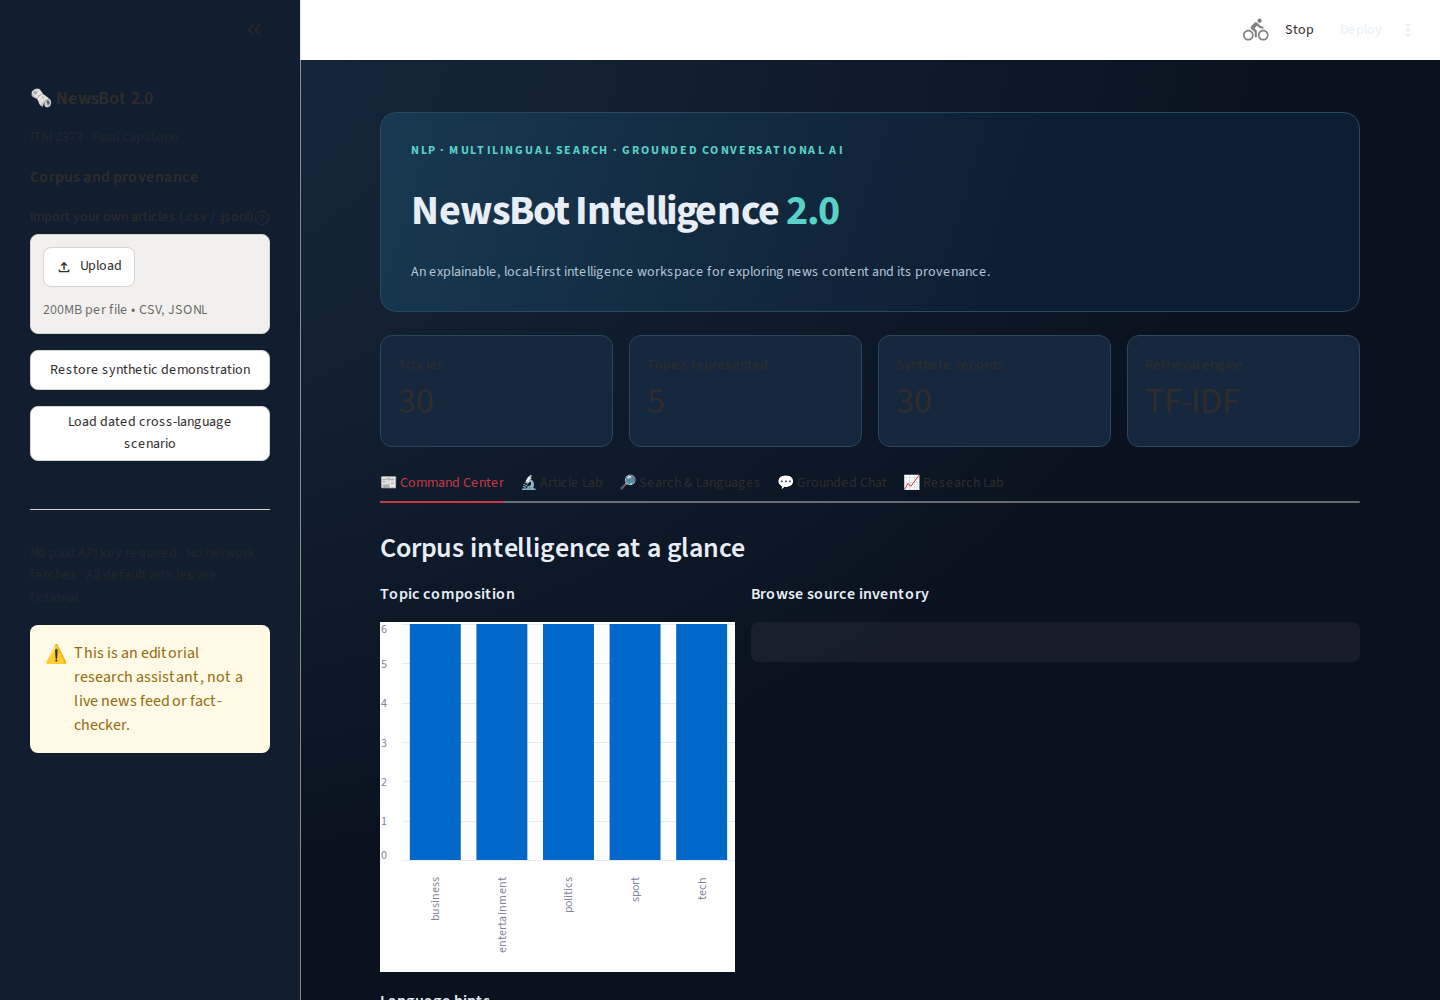

**Verified archived Chromium capture — 07-temporal-topic-discovery.png**

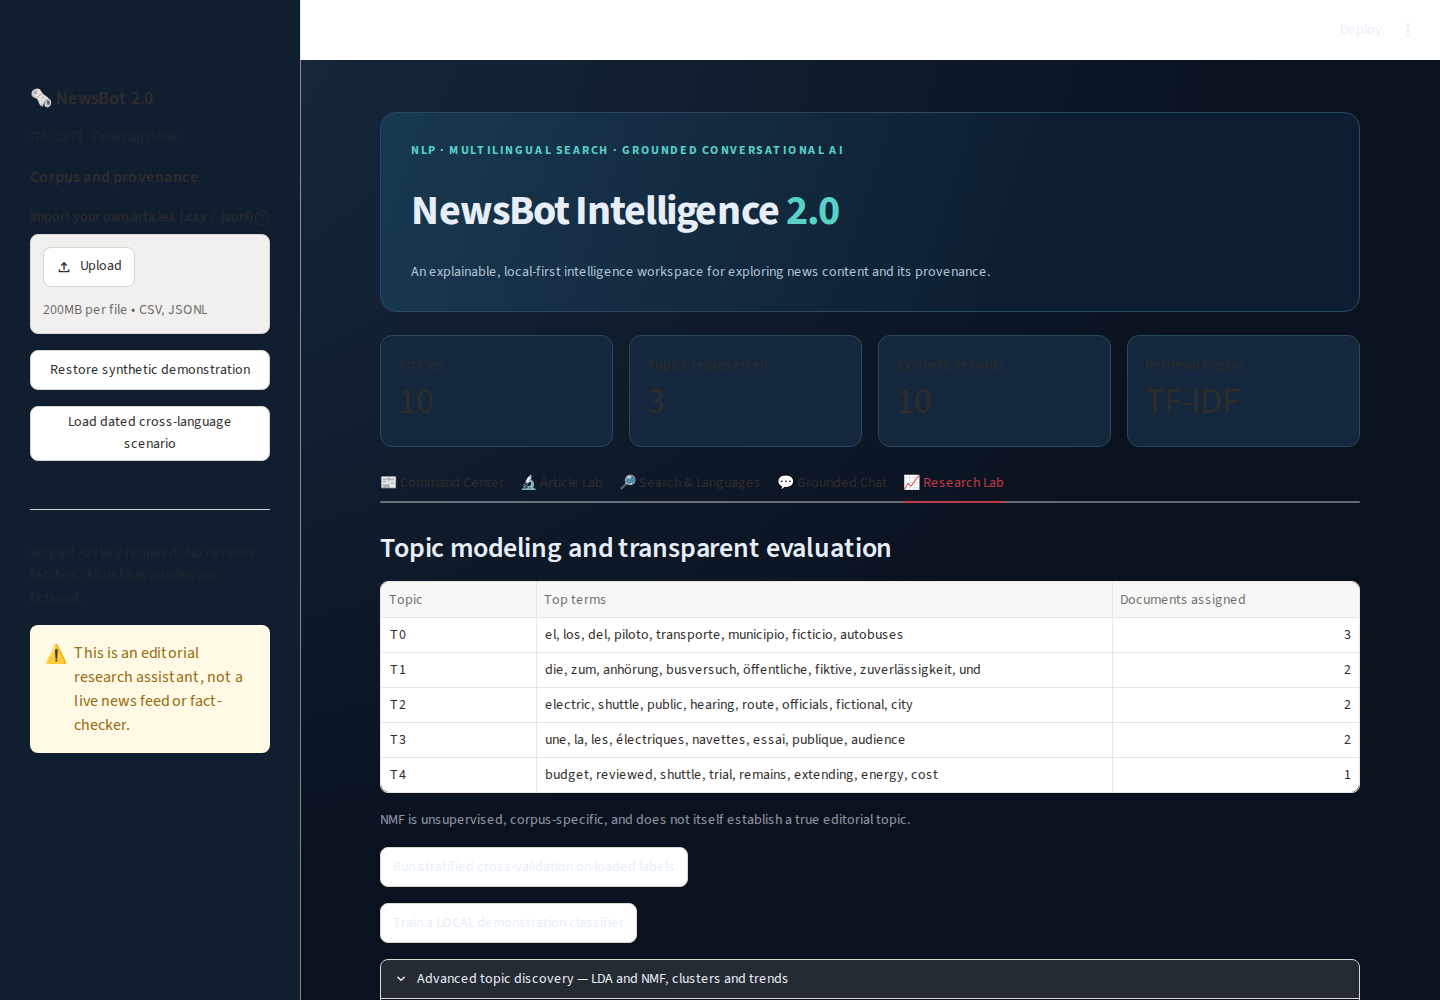

PASS | 07 | System integration and experimental research


In [9]:
# The test suite executes independently of narrative claims.
qa=subprocess.run([sys.executable,'-m','pytest','tests','-q'],capture_output=True,text=True)
print(qa.stdout); print(qa.stderr); (OUT/'pytest.log').write_text(qa.stdout+'\n'+qa.stderr,encoding='utf-8')
assert qa.returncode==0,'Test suite failed; review pytest.log'
browser=evidence('browser_results.json'); assert browser['status']=='passed'
print('Archived browser evidence: revision',browser['commit'],'| screens:',len(browser['screens']))
table(pd.DataFrame(browser['screens']))
for image_name in ['01-command-center.png','07-temporal-topic-discovery.png']:
    image_path=ROOT/'evidence'/'screenshots'/image_name
    if image_path.exists():
        display(Markdown('**Verified archived Chromium capture — '+image_name+'**')); display(Image(filename=str(image_path),width=950))
completed(7,'System integration and experimental research')

### Experimental findings and business relevance

The paired comparison tests feature representations under identical folds. Historical BBC cross-validation evaluates a different corpus and cannot be pooled with the synthetic scores. The application integrates these capabilities for editorial triage, source exploration and traceable reports. The proposed ROI model in the executive report is an illustrative scenario, not observed savings.

## 08 · Final synthesis and reviewer evidence

**Technical outcome:** modular content analysis, retrieval, multilingual access, generation and conversation are integrated through the same validated engine. **Research outcome:** the evidence supports controlled comparisons, real historical cross-validation and observed neural inference, but not production-level generalization. **Ethical outcome:** provenance, explicit uncertainty and human editorial review are central to the design.

| Limitation | Next scientific step |
| :--- | :--- |
| Small, selected synthetic probes | Independent blinded relevance annotations |
| Historical, single-corpus real data | Publisher- and time-separated evaluation |
| Uncalibrated classifier and retrieval scores | Calibration and answerability evaluation |
| Neural translation and generation not human-rated | Bilingual and factual consistency review |
| Local prototype rather than hardened production service | Authentication, quotas, monitoring, licensing, load tests |

Academic accountability: the repository documents AI assistance and the individual contribution record. Review actual contributions against the course requirements. The notebook does not infer instructor approval or a guaranteed grade.

In [10]:
assert len(STAGES)==7 and all(x['status']=='PASS' for x in STAGES)
completed(8,'Final synthesis and evidence export')
manifest={'source_revision':actual,'python':platform.python_version(),'created_utc':datetime.now(timezone.utc).isoformat(),'stages':STAGES,'test_exit_code':qa.returncode,'neural_rerun':RERUN_NEURAL,'real_bbc_rerun':RERUN_REAL_BBC,'scope':'Current runtime: CPU analysis, classification, topics, retrieval, chat, research and tests. Archived model and BBC evidence is separately labeled unless explicitly rerun.'}
saved_json('run_manifest.json',manifest)
import shutil
archive=shutil.make_archive(str(OUT),'zip',root_dir=OUT)
display(pd.DataFrame(STAGES)); print('ALL EIGHT INTEGRATED SECTIONS COMPLETED IN THIS RUNTIME.')
print('Evidence ZIP:',archive)
print('Save this notebook with outputs using File > Download > Download .ipynb.')

PASS | 08 | Final synthesis and evidence export


,section,name,status
0,1,Data exploration and preprocessing,PASS
1,2,Advanced classification,PASS
2,3,Topic modeling and advanced analytics,PASS
3,4,Language models and retrieval,PASS
4,5,Multilingual intelligence,PASS
5,6,Conversational interface,PASS
6,7,System integration and experimental research,PASS
7,8,Final synthesis and evidence export,PASS


ALL EIGHT INTEGRATED SECTIONS COMPLETED IN THIS RUNTIME.
Evidence ZIP: /content/NewsBot_Master_Evidence_5e415062.zip
Save this notebook with outputs using File > Download > Download .ipynb.


### References and reproducibility

- Blei, D. M., Ng, A. Y., & Jordan, M. I. (2003). Latent Dirichlet allocation. *Journal of Machine Learning Research, 3*, 993–1022.
- Lee, D. D., & Seung, H. S. (1999). Learning the parts of objects by non-negative matrix factorization. *Nature, 401*, 788–791.
- Reimers, N., & Gurevych, I. (2019). Sentence-BERT. *EMNLP*. [DOI](https://doi.org/10.18653/v1/D19-1410).
- Carbonell, J., & Goldstein, J. (1998). The use of MMR, diversity-based reranking. *SIGIR*. [DOI](https://doi.org/10.1145/290941.291025).
- [scikit-learn](https://scikit-learn.org/stable/) · [Sentence Transformers](https://www.sbert.net/) · [FLAN-T5 model card](https://huggingface.co/google/flan-t5-small) · [Argos Translate](https://argos-translate.readthedocs.io/) · [Streamlit](https://docs.streamlit.io/).
- [Historical BBC dataset source](https://www.kaggle.com/competitions/learn-ai-bbc/data). Rights reserved; no raw article bodies included in this evidence export.

**End of notebook — NewsBot Intelligence System 2.0.**